# Limbako Discovery Challenge — Baseline
**Unsupervised learning · Text clustering**

A researcher has returned from a remote region with **4,200 written statements** in a language called
**Limbako**. It appears in no dictionary, no search engine and no dataset on the internet.

No translator is available and no labels exist. The researcher suspects the statements cluster around
**6 topics**, as if different community members wrote about different parts of their daily lives.

**Your mission:** study the language from scratch, discover the hidden structure, and classify every statement.
You cannot look up the words and you cannot use a pretrained model — only the text itself.

| | |
|---|---|
| **Train** | `train_unlabeled.csv` — 4,200 statements, **no labels** |
| **Test** | `test.csv` — 2,400 statements (`id`, `statement`) |
| **Labels** | `agriculture`, `education`, `finance`, `health`, `sports`, `technology` |
| **Metric** | **Macro F1-score** |
| **Submission** | `id,label` — `label` must be one of the six names above |

### What you need to do
1. **Explore** the vocabulary — which words appear together? Which are rare but consistent?
2. **Cluster** the statements into 6 groups with unsupervised methods
3. **Name** each group — figure out which topic it represents
4. **Predict** the topic of every test statement

### Notebook structure
1. Setup & load data
2. Explore the vocabulary
3. Baseline: encode & cluster
4. Name each cluster
5. Visualise & evaluate without labels
6. Generate submission

## 1. Setup & Load Data

In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score

SEED = 42
K    = 6
LABELS = ['agriculture', 'education', 'finance', 'health', 'sports', 'technology']

# Works on Kaggle and locally (put the competition files in ./data)
COMPETITION = 'limbako-classification'
CANDIDATES  = [Path(f'/kaggle/input/competitions/{COMPETITION}'), Path(f'/kaggle/input/{COMPETITION}'), Path('data')]
DATA_DIR    = next(p for p in CANDIDATES if p.exists())

train = pd.read_csv(DATA_DIR / 'train_unlabeled.csv')
test  = pd.read_csv(DATA_DIR / 'test.csv')

print(f'Training set : {len(train)} statements (no labels)')
print(f'Test set     : {len(test)} statements')
train.head(10)

Training set : 4200 statements (no labels)
Test set     : 2400 statements


,statement
0,haba upasuaji afyani nachanja ila simu damu
1,penu uwanja nanulia mbali elimu siku
2,naprogramu umwagiliaji mbali algoriti iko nkulu
3,rizu nafe ko nauza utafiti karibu profesa
4,faida kodika nahakiki mbali dola mpya
5,sukulu bali mtihani napiga chuoni nyuma elimu
6,foli nafuga kati fursa mpya wo mgonjwa
7,mtihani gumu wo somo elimika napalilia kale
8,ugonjwa hospitalini naangalia kati nguvu baya
9,kahawa mazaoni navuna kati maendeleo kali


## 2. Explore the Vocabulary

With no labels, we start with the words themselves. Words that appear consistently in a *subset*
of statements are likely topic signals; words that appear everywhere are likely grammar.

In [2]:
all_tokens = ' '.join(train['statement']).split()
vocab      = Counter(all_tokens)

print(f'Total tokens  : {len(all_tokens):,}')
print(f'Unique words  : {len(vocab)}')
print(f'Avg statement : {len(all_tokens) / len(train):.1f} words\n')
print('Top 40 most frequent words:')
for word, count in vocab.most_common(40):
    print(f'  {word:20s} {count:5d}')

Total tokens  : 26,442
Unique words  : 298
Avg statement : 6.3 words

Top 40 most frequent words:
  kale                   267
  mwaka                  263
  wiki                   242
  damu                   241
  hari                   239
  hivi                   236
  leo                    230
  tangu                  227
  keshu                  220
  siku                   219
  nje                    218
  karibu                 216
  kati                   206
  mbele                  206
  pande                  205
  chini                  205
  ndani                  197
  ila                    196
  bali                   192
  wala                   192
  juu                    189
  mbali                  188
  ni                     188
  ama                    186
  rizu                   184
  yesu                   183
  nyuma                  181
  za                     180
  ba                     180
  ndi                    180
  kwi                    178
  n

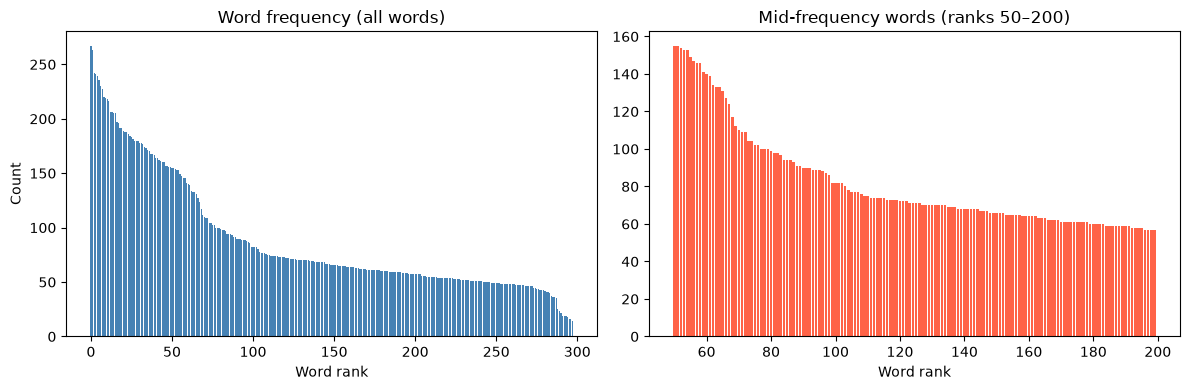

In [3]:
counts = np.array(sorted(vocab.values(), reverse=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(len(counts)), counts, color='steelblue')
axes[0].set_title('Word frequency (all words)')
axes[0].set_xlabel('Word rank')
axes[0].set_ylabel('Count')

axes[1].bar(range(50, 200), counts[50:200], color='tomato')
axes[1].set_title('Mid-frequency words (ranks 50–200)')
axes[1].set_xlabel('Word rank')
plt.tight_layout()
plt.show()

## 3. Baseline: Encode & Cluster

We need two things:

- **An encoder** that turns each statement into a vector. Here: a word-count matrix (`CountVectorizer`) —
one row per statement, one column per word.
- **A clustering model** that groups similar vectors. Here: **LDA (Latent Dirichlet Allocation)**,
which discovers "topics" as groups of words that tend to appear together.

**This is the cell to modify.** Try other encoders, models, distance metrics and hyperparameters.

In [4]:
# ── Encoder ───────────────────────────────────────────────────────────────────
count_vec   = CountVectorizer(max_features=500, min_df=2)
X_train_cnt = count_vec.fit_transform(train['statement'])
X_test_cnt  = count_vec.transform(test['statement'])

# ── Model ─────────────────────────────────────────────────────────────────────
lda = LatentDirichletAllocation(
    n_components=K,
    random_state=SEED,
    max_iter=300,
    learning_method='batch',
    doc_topic_prior=0.1,
    topic_word_prior=0.01,
)
train_topic_dist = lda.fit_transform(X_train_cnt)
test_topic_dist  = lda.transform(X_test_cnt)

train_cluster_ids = train_topic_dist.argmax(axis=1)
test_cluster_ids  = test_topic_dist.argmax(axis=1)

# ── Inspect topics ────────────────────────────────────────────────────────────
feature_names = count_vec.get_feature_names_out()
print('Top 12 words per topic:')
for topic_id, topic_vec in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic_vec.argsort()[:-13:-1]]
    print(f'\nTopic {topic_id} ({(train_cluster_ids == topic_id).sum()} statements): {top_words}')

Top 12 words per topic:

Topic 0 (716 statements): ['ubingwa', 'timu', 'kikosi', 'mchezaji', 'jamii', 'matokeo', 'jeraha', 'kipa', 'naongoza', 'mpira', 'fursa', 'ligi']

Topic 1 (763 statements): ['kami', 'chuo', 'siri', 'sera', 'mavuno', 'umwagiliaji', 'nafaka', 'mbele', 'mkulima', 'bustani', 'ghala', 'naendeleza']

Topic 2 (640 statements): ['elimu', 'taarifa', 'au', 'somo', 'ko', 'kitabu', 'nashughulikia', 'profesa', 'ujuzi', 'mwalimu', 'data', 'diploma']

Topic 3 (783 statements): ['foli', 'wingu', 'maendeleo', 'hifadi', 'mtandao', 'simu', 'kodishi', 'nahifadi_t', 'seva', 'kale', 'nywila', 'roboti']

Topic 4 (587 statements): ['waku', 'deni', 'hasara', 'gharama', 'faida', 'mpango', 'fedha', 'kodi', 'mali', 'napanga', 'riba', 'nahifadi_f']

Topic 5 (711 statements): ['nachangia', 'mgonjwa', 'tiba', 'afya', 'naangalia', 'daktari', 'chanjo', 'haki', 'naagiza', 'ugonjwa', 'vitamini', 'hospitali']


## 4. Name Each Cluster

Look at the top words above and decide which category each topic corresponds to.
The mapping below is only a placeholder — **fixing it is a key part of the challenge.**
Each of the six labels should be used exactly once.

In [5]:
TOPIC_TO_LABEL = {
    0: 'agriculture',
    1: 'education',
    2: 'finance',
    3: 'health',
    4: 'sports',
    5: 'technology',
}
assert sorted(TOPIC_TO_LABEL.values()) == LABELS, 'Use each label exactly once'

for c in range(K):
    print(f'Topic {c} -> {TOPIC_TO_LABEL[c]:12s}: {(train_cluster_ids == c).sum()} statements')

Topic 0 -> agriculture : 716 statements
Topic 1 -> education   : 763 statements
Topic 2 -> finance     : 640 statements
Topic 3 -> health      : 783 statements
Topic 4 -> sports      : 587 statements
Topic 5 -> technology  : 711 statements


## 5. Visualise & Evaluate Without Labels

We have no ground truth, but we can still look at how well separated the clusters are.

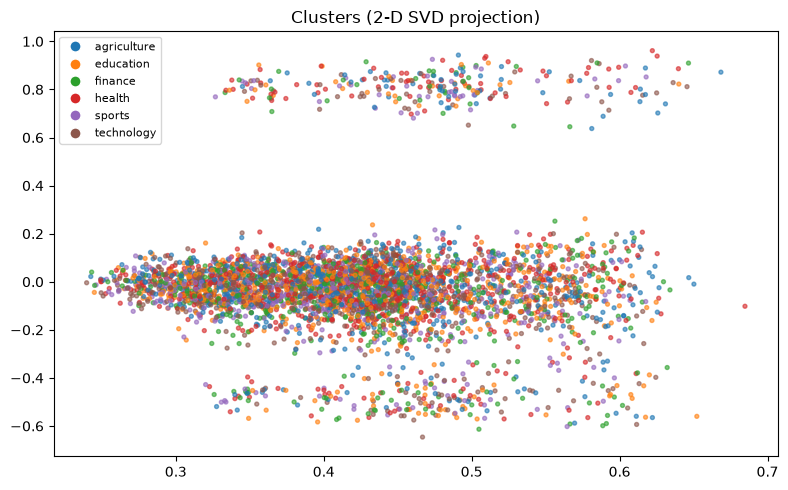

Silhouette score (cosine): 0.0115   (range -1 to 1, higher is better)


In [6]:
X_2d = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X_train_cnt)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=train_cluster_ids, cmap='tab10', s=8, alpha=0.6, vmin=0, vmax=9)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab10(i), markersize=8)
           for i in range(K)]
ax.legend(handles, [TOPIC_TO_LABEL[i] for i in range(K)], loc='best', fontsize=8)
ax.set_title('Clusters (2-D SVD projection)')
plt.tight_layout()
plt.show()

sil = silhouette_score(normalize(X_train_cnt), train_cluster_ids, metric='cosine',
                       sample_size=1000, random_state=SEED)
print(f'Silhouette score (cosine): {sil:.4f}   (range -1 to 1, higher is better)')

## 6. Generate Submission

In [7]:
submission = pd.DataFrame({
    'id':    test['id'],
    'label': [TOPIC_TO_LABEL[c] for c in test_cluster_ids],
})
submission.to_csv('submission.csv', index=False)

print(f'Saved {len(submission)} predictions to submission.csv\n')
print(submission['label'].value_counts())
submission.head()

Saved 2400 predictions to submission.csv

label
education      451
technology     431
health         426
agriculture    417
finance        355
sports         320
Name: count, dtype: int64


,id,label
0,0,agriculture
1,1,health
2,2,sports
3,3,sports
4,4,finance
